[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/hentablihamza/fingerprint-similarity-guide/blob/main/notebooks/06_benchmark_activity_cliffs.ipynb)

# 06 · Benchmark 3 — Activity Cliffs

*Fingerprint & Similarity Guide · Hamza Hentabli, Ph.D. · ~50 min*

The similarity principle says *similar molecules have similar activity*. **Activity cliffs** are where that breaks: two molecules a fingerprint calls nearly identical, yet their potencies differ by orders of magnitude. Cliffs wreck similarity-based predictions, and — crucially — **how many cliffs you 'see' depends on the fingerprint**. We quantify that on 6,871 ChEMBL EGFR inhibitors with measured pIC50.

**Learning objectives.** By the end of this notebook you will be able to:

- define an activity cliff and the Structure–Activity Landscape Index (SALI)
- find real activity cliffs in the EGFR data and inspect them
- measure, per fingerprint, the fraction of near-neighbour pairs that are cliffs
- see why a 'blurry' fingerprint (MACCS) manufactures far more apparent cliffs

In [1]:
# Setup: on Google Colab this installs dependencies and clones the repo so the
# cached data and the shared `fsg` helper module are available. Running locally,
# install requirements.txt once and this cell just locates the files.
import os, sys, subprocess

IN_COLAB = "google.colab" in sys.modules
OFFLINE = os.environ.get("FSG_OFFLINE", "0") == "1"   # CI sets this; no notebook needs the network
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "rdkit", "scikit-learn", "scipy", "pandas", "matplotlib"], check=True)
    if not os.path.isdir("fingerprint-similarity-guide"):
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/hentablihamza/fingerprint-similarity-guide.git"], check=True)
    ROOT = "fingerprint-similarity-guide"
else:
    ROOT = ".." if os.path.isdir("../data") else "."
DATA_DIR = os.path.join(ROOT, "data")
if ROOT not in sys.path:
    sys.path.insert(0, ROOT)
import fsg   # shared fingerprint factory + metrics + evaluation

print("Colab:", IN_COLAB, "| offline:", OFFLINE, "| data:", DATA_DIR)
print("Fingerprints available:", ", ".join(fsg.FP_NAMES))

Colab: False | offline: True | data: ../data
Fingerprints available: ECFP4-1024, ECFP4-2048, ECFP6-2048, ECFP4-counts, FCFP4-2048, RDKit, AtomPair, Torsion, MACCS, Avalon


In [2]:
import numpy as np, pandas as pd
egfr = fsg.load_mols(pd.read_csv(f"{DATA_DIR}/egfr_chembl37_ic50.csv"))
print(f"{len(egfr)} EGFR inhibitors with pIC50 (p_activity)")
print(egfr[["compound_id","p_activity"]].describe().round(2).T)

6871 EGFR inhibitors with pIC50 (p_activity)
             count  mean   std  min   25%   50%  75%   max
p_activity  6871.0   7.0  1.28  4.0  6.07  7.05  8.0  11.0


## 1. What is an activity cliff?

A pair of molecules is an **activity cliff** when their structural similarity is high (here Tanimoto ≥ 0.70) but their activity difference is large (|ΔpIC50| ≥ 2, i.e. ≥100× in IC50). The **SALI** score formalises it:

$$ \text{SALI}_{ij} = \frac{|\,\text{pIC50}_i - \text{pIC50}_j\,|}{1 - \text{sim}(i,j)} $$

Big activity gap + near-identical structure ⇒ huge SALI ⇒ a cliff that any similarity-based model will fall off.

## 2. Find a real cliff in the EGFR set

We scan for a pair with high ECFP4 Tanimoto but a large potency gap, and look at it.

Cliff: CHEMBL5173517 (pIC50 5.88) vs CHEMBL6145857 (pIC50 10.00)
  ECFP4 Tanimoto = 1.000, |dpIC50| = 4.12, SALI = 4115000000.0


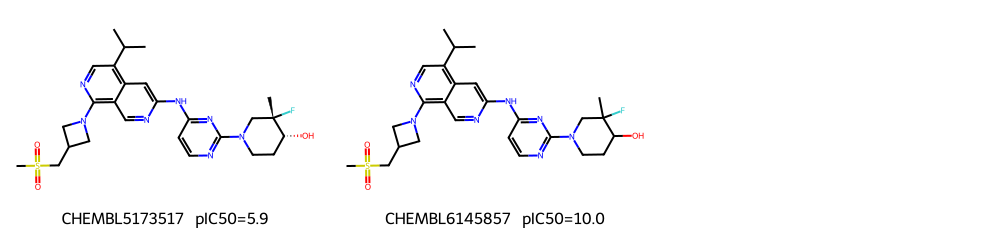

In [3]:
mfp = fsg.make_fps("ECFP4-2048", list(egfr["mol"]))
y = egfr["p_activity"].to_numpy()
best = None
for i in range(len(mfp)):
    sims = fsg.bulk_similarity("tanimoto", mfp[i], mfp[i+1:])
    for off, s in enumerate(sims):
        j = i + 1 + off
        if s >= 0.8:
            sali = abs(y[i]-y[j]) / (1 - s + 1e-9)
            if best is None or sali > best[0]:
                best = (sali, i, j, s, abs(y[i]-y[j]))
sali, i, j, s, dact = best
print(f"Cliff: {egfr.compound_id[i]} (pIC50 {y[i]:.2f}) vs {egfr.compound_id[j]} (pIC50 {y[j]:.2f})")
print(f"  ECFP4 Tanimoto = {s:.3f}, |dpIC50| = {dact:.2f}, SALI = {sali:.1f}")
from rdkit.Chem import Draw
Draw.MolsToGridImage([egfr.mol[i], egfr.mol[j]],
    legends=[f"{egfr.compound_id[i]}  pIC50={y[i]:.1f}", f"{egfr.compound_id[j]}  pIC50={y[j]:.1f}"],
    subImgSize=(330, 240))

A tiny structural change flips potency by orders of magnitude — the fingerprint barely registers the difference, but the biology does. No fingerprint can 'fix' a true cliff; the question is **how many spurious cliffs a fingerprint invents** by calling dissimilar molecules similar.

## 3. Cliffs per fingerprint — the method, computed live

For two fingerprints we count, on a fixed 1,500-compound sample, the near-neighbour pairs (Tanimoto ≥ 0.70) and what fraction of them are cliffs (|ΔpIC50| ≥ 2). This is the exact computation `scripts/run_benchmarks.py` runs for all 10 fingerprints.

In [4]:
samp = egfr.sample(n=1500, random_state=42).reset_index(drop=True)
ys = samp["p_activity"].to_numpy()
def cliff_stats(name, SIM_T=0.70, CLIFF_D=2.0):
    fps = fsg.make_fps(name, list(samp["mol"]))
    n_nn = n_cliff = 0
    for a in range(len(fps)):
        sims = fsg.bulk_similarity("tanimoto", fps[a], fps[a+1:])
        for off, sv in enumerate(sims):
            b = a + 1 + off
            if sv >= SIM_T:
                n_nn += 1
                if abs(ys[a]-ys[b]) >= CLIFF_D:
                    n_cliff += 1
    return n_nn, n_cliff
for name in ["ECFP4-2048", "MACCS"]:
    nn, cl = cliff_stats(name)
    print(f"{name:12s} near-neighbour pairs={nn:6d}  cliffs={cl:5d}  cliff fraction={cl/nn:.3f}")

ECFP4-2048   near-neighbour pairs=  1825  cliffs=   48  cliff fraction=0.026


MACCS        near-neighbour pairs= 80604  cliffs=14574  cliff fraction=0.181


## 4. The full picture (all fingerprints)

The committed results cover every fingerprint on the same 1,500-compound sample.

In [5]:
import json, os
import pandas as pd
DOCS_DIR = os.path.join(ROOT, "docs")
RESULTS = json.load(open(os.path.join(DOCS_DIR, "benchmark_results.json")))
print("Loaded committed benchmark results from docs/benchmark_results.json")

Loaded committed benchmark results from docs/benchmark_results.json


In [6]:
b3 = RESULTS["benchmark3_activity_cliffs"]["scores"]
cliff_df = pd.DataFrame([{"fingerprint": k, **v} for k, v in b3.items()])
cliff_df = cliff_df.sort_values("n_near_neighbor_pairs", ascending=False).reset_index(drop=True)
cliff_df

,fingerprint,n_near_neighbor_pairs,n_cliff_pairs,cliff_fraction,spearman_sim_vs_activity_closeness
0,MACCS,80604,14574,0.181,0.130
1,RDKit,28407,1763,0.062,0.128
2,Avalon,8301,517,0.062,0.124
3,FCFP4-2048,4822,171,0.035,0.155
4,AtomPair,3546,103,0.029,0.151
5,Torsion,3134,137,0.044,0.155
6,ECFP4-counts,2074,64,0.031,0.149
7,ECFP4-1024,1926,54,0.028,0.144
8,ECFP4-2048,1825,48,0.026,0.150
9,ECFP6-2048,1028,24,0.023,0.142


Two things jump out. **MACCS** flags an *order of magnitude* more 'near-neighbour' pairs than ECFP — and a far higher fraction of them are cliffs (because MACCS calls many genuinely different molecules similar, so their activities naturally differ). **ECFP6** (most specific) flags the fewest. The weak, positive Spearman correlation between similarity and activity closeness confirms the similarity principle holds only loosely.

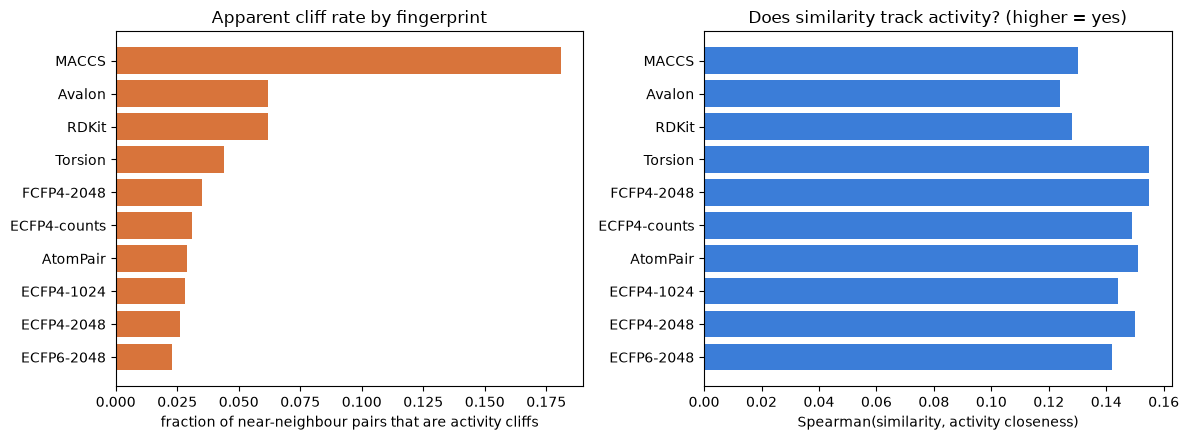

In [7]:
import matplotlib.pyplot as plt
d = cliff_df.sort_values("cliff_fraction")
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].barh(d["fingerprint"], d["cliff_fraction"], color="#d8743b")
ax[0].set_xlabel("fraction of near-neighbour pairs that are activity cliffs")
ax[0].set_title("Apparent cliff rate by fingerprint")
ax[1].barh(d["fingerprint"], d["spearman_sim_vs_activity_closeness"], color="#3b7dd8")
ax[1].set_xlabel("Spearman(similarity, activity closeness)")
ax[1].set_title("Does similarity track activity? (higher = yes)")
plt.tight_layout(); plt.show()

## Summary

- **Activity cliffs** are real and no fingerprint removes them — they are biology, not encoding.
- **The number of apparent cliffs depends on the fingerprint**: coarse MACCS manufactures many more 'near neighbours' and cliffs; specific ECFP6 the fewest.
- Similarity tracks activity only **weakly** (low Spearman) — expect similarity-based models to have a cliff-shaped error floor.

Next: turn similarity into actual predictions — nearest-neighbour QSAR.

### ✏️ Exercise 1

Recompute the SALI for the cliff pair above using FCFP4 instead of ECFP4. Does the feature fingerprint see them as more or less similar?

<details>
<summary><b>Show solution</b></summary>

```python
fa = fsg.make_fp("FCFP4-2048", egfr.mol[i]); fb = fsg.make_fp("FCFP4-2048", egfr.mol[j])
s2 = fsg.similarity("tanimoto", fa, fb)
print("FCFP4 Tanimoto:", round(s2,3), "| ECFP4 was", round(s,3))
```

</details>

### ✏️ Exercise 2

Which fingerprint has the HIGHEST Spearman(similarity, activity-closeness), i.e. best respects the similarity principle on this set?

<details>
<summary><b>Show solution</b></summary>

```python
print(cliff_df.sort_values("spearman_sim_vs_activity_closeness", ascending=False)[["fingerprint","spearman_sim_vs_activity_closeness"]].head())
```

</details>